In [116]:
from pathlib import Path
import sqlite3
import pandas as pd

# Find the project folder from this notebook's location.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Open the project's SQLite database.
database_path = project_root / "data" / "jobs.db"
connection = sqlite3.connect(database_path)

# Read the cleaned postings table into a pandas DataFrame.
jobs = pd.read_sql_query(
    "SELECT * FROM job_postings_clean",
    connection,
)

# Close the database connection because we have finished reading.
connection.close()

print("Rows:", len(jobs))
print("Columns:", jobs.columns.tolist())
display(jobs.head(3))

Rows: 29425
Columns: ['Uniq Id', 'Crawl Timestamp', 'Job Title', 'Job Salary', 'Job Experience Required', 'Key Skills', 'Role Category', 'Location', 'Functional Area', 'Industry', 'Role', 'salary_min_lpa', 'salary_max_lpa', 'salary_mid_lpa']


,Uniq Id,Crawl Timestamp,Job Title,Job Salary,Job Experience Required,Key Skills,Role Category,Location,Functional Area,Industry,Role,salary_min_lpa,salary_max_lpa,salary_mid_lpa
0,9be62c49a0b7ebe982a4af1edaa7bc5f,2019-07-05 01:46:07 +0000,Digital Media Planner,Not Disclosed by Recruiter,5 - 10 yrs,Media Planning| Digital Media,Advertising,Mumbai,"Marketing , Advertising , MR , PR , Media Plan...","Advertising, PR, MR, Event Management",Media Planning Executive/Manager,NaN,NaN,NaN
1,3c52d436e39f596b22519da2612f6a56,2019-07-06 08:04:50 +0000,Online Bidding Executive,Not Disclosed by Recruiter,2 - 5 yrs,pre sales| closing| software knowledge| client...,Retail Sales,Pune,"Sales , Retail , Business Development","IT-Software, Software Services",Sales Executive/Officer,NaN,NaN,NaN
2,ffad8a2396c60be2bf6d0e2ff47c58d4,2019-08-05 15:50:44 +0000,Trainee Research/ Research Executive- Hi- Tech...,Not Disclosed by Recruiter,0 - 1 yrs,Computer science| Fabrication| Quality check| ...,R&D,Gurgaon,"Engineering Design , R&D","Recruitment, Staffing",R&D Executive,NaN,NaN,NaN


In [117]:
# Keep rows where the parsed salary midpoint exists and is positive.
model_data = jobs.loc[
    jobs["salary_mid_lpa"].notna()
    & (jobs["salary_mid_lpa"] > 0)
].copy()

print("Rows with a usable salary target:", len(model_data))
print("Rows without a usable salary target:", len(jobs) - len(model_data))

# Show the salary range so we can spot suspicious values before modeling.
display(
    model_data["salary_mid_lpa"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)

Rows with a usable salary target: 7739
Rows without a usable salary target: 21686


count    7739.000000
mean        6.208537
std         7.142809
min         0.075000
50%         3.750000
90%        13.000000
95%        17.500000
99%        37.500000
max       100.000000
Name: salary_mid_lpa, dtype: float64

In [118]:
# Show the 15 lowest parsed salaries with their original salary text.
lowest_salaries = model_data.nsmallest(15, "salary_mid_lpa")[
    ["Job Title", "Job Salary", "salary_min_lpa", "salary_max_lpa", "salary_mid_lpa"]
]

display(lowest_salaries)

# Show the 15 highest parsed salaries for the same inspection.
highest_salaries = model_data.nlargest(15, "salary_mid_lpa")[
    ["Job Title", "Job Salary", "salary_min_lpa", "salary_max_lpa", "salary_mid_lpa"]
]

display(highest_salaries)

,Job Title,Job Salary,salary_min_lpa,salary_max_lpa,salary_mid_lpa
9805,Trainee Marine Engineer,"5,000 - 10,000 PA.",0.05,0.10,0.075
29088,Recruitment Specialist,"10,000 PA.",0.10,0.10,0.100
28997,Java Developer,"15,000 - 20,000 PA.",0.15,0.20,0.175
10965,Senior Firmware Engineer,"15,000 - 25,000 PA.",0.15,0.25,0.200
17298,Manager - Finance,"15,000 - 25,000 PA.",0.15,0.25,0.200
3569,Urgent|freelance Trainer in General Insurance|...,"50,000 PA.",0.50,0.50,0.500
11527,Walk In Interview - HR Intern - Andheri (chakala),"50,000 PA.",0.50,0.50,0.500
15040,Area Sales Executive,"50,000 PA.",0.50,0.50,0.500
22259,Tcs Hiring for Python Developer for Kolkata Lo...,"50,000 PA.",0.50,0.50,0.500
2329,Internship in Digital Marketing,Stipend-4000-5000/- per month,0.48,0.60,0.540


,Job Title,Job Salary,salary_min_lpa,salary_max_lpa,salary_mid_lpa
14900,Project Manager (automotive Domain - Bangalore...,INR 1 Cr & above PA.,100.0,100.0,100.0
16687,VP- Business Finance- Mumbai (urgent),1 Cr & above PA.,100.0,100.0,100.0
20328,SDET,INR 1 Cr & above PA.,100.0,100.0,100.0
21495,Urgent Requirement for JavaScript Developer at...,"1,00,00,000 PA.",100.0,100.0,100.0
23216,.Net (C# Winforms),INR 1 Cr & above PA.,100.0,100.0,100.0
28973,Chief Digital Officer for a Large Bank,"1,00,00,000 PA.",100.0,100.0,100.0
384,VP / Sr.vp Fire,"50,00,000 - 1,00,00,000 PA.",50.0,100.0,75.0
1647,Urgent Opening for VP - Sales with Hosiery Com...,"50,00,000 - 1 Cr & above PA.",50.0,100.0,75.0
12621,Big Data Software Engineering Director,"50,00,000 - 1 Cr & above PA.",50.0,100.0,75.0
16591,Thu Aug IST 8484,"50,00,000 - 1 Cr & above PA.",50.0,100.0,75.0


In [119]:
# Select salary descriptions whose parsed midpoint is below 0.01 LPA.
suspicious_rows = model_data.loc[
    model_data["salary_mid_lpa"] < 0.01,
    ["Job Title", "Job Salary", "salary_min_lpa", "salary_max_lpa", "salary_mid_lpa"],
]

print("Suspicious rows:", len(suspicious_rows))

# Show complete text instead of shortening long descriptions.
with pd.option_context("display.max_colwidth", None):
    display(suspicious_rows)

Suspicious rows: 0


,Job Title,Job Salary,salary_min_lpa,salary_max_lpa,salary_mid_lpa


In [120]:
# Find benefit descriptions that were previously mistaken for salaries.
benefit_rows = jobs.loc[
    jobs["Job Salary"].str.contains(
        "annual Paid Leaves|half yearly increments",
        case=False,
        na=False,
    ),
    ["Job Title", "Job Salary", "salary_mid_lpa"],
]

display(benefit_rows)


,Job Title,Job Salary,salary_mid_lpa
1736,Govt. Job Interviews For Doctors in Saudi Arabia,* annual Paid Leaves for 30-45 days * tax Free...,NaN
13621,MOH Govt. Job For Doctors For Saudi Arabia.,* annual Paid Leaves for 30-45 days * tax Free...,NaN
14281,Internal / General Medicine Doctors Interview ...,* Annual Paid Leaves for 30-45 days * Tax Free...,NaN
22212,Online Live Teaching Professionals - Asst. Pro...,"5 day's working, Breakfast and Lunch on the ho...",NaN


In [121]:
from pathlib import Path
import sys

# Find the project root from the notebook's current folder.
project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

# Let Python find project modules such as src.salary_parser.
sys.path.insert(0, str(project_root))

from src.salary_parser import parse_salary_lpa

examples = [
    "annual Paid Leaves for 30-45 days; tax Free Salary",
    "5 day's working, Breakfast and Lunch on the house, half yearly increments",
]

for text in examples:
    print(text)
    print("Parsed result:", parse_salary_lpa(text))
    print()
    

annual Paid Leaves for 30-45 days; tax Free Salary
Parsed result: None

5 day's working, Breakfast and Lunch on the house, half yearly increments
Parsed result: None



In [122]:
benefit_rows = jobs.loc[
    jobs["Job Salary"].str.contains(
        "annual Paid Leaves|half yearly increments",
        case=False,
        na=False,
    ),
    ["Job Title", "Job Salary", "salary_mid_lpa"],
]

display(benefit_rows)

,Job Title,Job Salary,salary_mid_lpa
1736,Govt. Job Interviews For Doctors in Saudi Arabia,* annual Paid Leaves for 30-45 days * tax Free...,NaN
13621,MOH Govt. Job For Doctors For Saudi Arabia.,* annual Paid Leaves for 30-45 days * tax Free...,NaN
14281,Internal / General Medicine Doctors Interview ...,* Annual Paid Leaves for 30-45 days * Tax Free...,NaN
22212,Online Live Teaching Professionals - Asst. Pro...,"5 day's working, Breakfast and Lunch on the ho...",NaN


In [123]:
import importlib
import sqlite3

import src.salary_parser as salary_parser
import src.cleaning_pipeline as cleaning_pipeline

# Reload the saved files so the notebook uses your latest edits.
importlib.reload(salary_parser)
importlib.reload(cleaning_pipeline)

# Recalculate salary columns and update job_postings_clean.
cleaning_pipeline.main()

# Read the updated table from this project's database.
connection = sqlite3.connect(project_root / "data" / "jobs.db")
jobs = pd.read_sql_query("SELECT * FROM job_postings_clean", connection)
connection.close()

# Check the benefit descriptions again.
benefit_rows = jobs.loc[
    jobs["Job Salary"].str.contains(
        "annual Paid Leaves|half yearly increments",
        case=False,
        na=False,
    ),
    ["Job Title", "Job Salary", "salary_mid_lpa"],
]

display(benefit_rows)

Raw rows: 30000
Clean rows: 29425
Updated table: job_postings_clean


,Job Title,Job Salary,salary_mid_lpa
1736,Govt. Job Interviews For Doctors in Saudi Arabia,* annual Paid Leaves for 30-45 days * tax Free...,NaN
13621,MOH Govt. Job For Doctors For Saudi Arabia.,* annual Paid Leaves for 30-45 days * tax Free...,NaN
14281,Internal / General Medicine Doctors Interview ...,* Annual Paid Leaves for 30-45 days * Tax Free...,NaN
22212,Online Live Teaching Professionals - Asst. Pro...,"5 day's working, Breakfast and Lunch on the ho...",NaN


In [124]:
# Keep postings that have a positive parsed salary midpoint.
model_data = jobs.loc[
    jobs["salary_mid_lpa"].notna()
    & (jobs["salary_mid_lpa"] > 0)
].copy()

print("Rows with a usable salary target:", len(model_data))
print("Rows excluded:", len(jobs) - len(model_data))

# Summarize typical salaries and the high end of the distribution.
display(
    model_data["salary_mid_lpa"].describe(
        percentiles=[0.5, 0.9, 0.95, 0.99]
    )
)



Rows with a usable salary target: 7739
Rows excluded: 21686


count    7739.000000
mean        6.208537
std         7.142809
min         0.075000
50%         3.750000
90%        13.000000
95%        17.500000
99%        37.500000
max       100.000000
Name: salary_mid_lpa, dtype: float64

In [125]:
from sklearn.model_selection import train_test_split

# Use job details as inputs. Do not include salary columns, IDs, or crawl dates.
feature_columns = [
    "Job Title",
    "Role",
    "Location",
    "Job Experience Required",
    "Key Skills",
    "Role Category",
    "Functional Area",
    "Industry",
]

# X contains the inputs; y contains the salary value the model should predict.
X = model_data[feature_columns].fillna("")
y = model_data["salary_mid_lpa"].astype(float)

# Hold back 20% of the rows for an independent model evaluation.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Input columns:", X_train.columns.tolist())
print("Training target median:", y_train.median())

Training rows: 6191
Test rows: 1548
Input columns: ['Job Title', 'Role', 'Location', 'Job Experience Required', 'Key Skills', 'Role Category', 'Functional Area', 'Industry']
Training target median: 3.75


In [126]:
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, r2_score

# Create a baseline that always predicts the training-set median salary.
baseline_model = DummyRegressor(strategy="median")

# "Fit" records the median from the training targets.
baseline_model.fit(X_train, y_train)

# Predict one salary for each test posting.
baseline_predictions = baseline_model.predict(X_test)

# Measure average absolute error in LPA and how much variation is explained.
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
baseline_r2 = r2_score(y_test, baseline_predictions)

print(f"Baseline MAE: {baseline_mae:.2f} LPA")
print(f"Baseline R²: {baseline_r2:.3f}")

Baseline MAE: 3.94 LPA
Baseline R²: -0.123


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Ridge
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

text_columns = ["Job Title", "Key Skills", "Functional Area"]
categorical_columns = [
    "Role",
    "Location",
    "Job Experience Required",
    "Role Category",
    "Industry",
]


def prepare_model_inputs(frame):
    """Combine text fields after removing salary mentions from them."""
    prepared = frame.copy()

    # Remove salary figures from text so they cannot reveal the target.
    for column in text_columns:
        prepared[column] = prepared[column].map(remove_salary_mentions)

    # Combine the cleaned text fields.
    prepared["job_text"] = (
        prepared["Job Title"]
        + " "
        + prepared["Key Skills"]
        + " "
        + prepared["Functional Area"]
    )

    # Keep category and experience features in their own columns.
    return prepared.drop(columns=text_columns)


X_train_prepared = prepare_model_inputs(X_train)
X_test_prepared = prepare_model_inputs(X_test)

# Apply TF-IDF to words and one-hot encoding to job categories.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
            ),
            "job_text",
        ),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns,
        ),
    ]
)

# Bundle preprocessing and Ridge regression into one repeatable model.
salary_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("regressor", Ridge(alpha=1.0)),
    ]
)

# Learn from training data, then evaluate on the held-back test data.
salary_model.fit(X_train_prepared, y_train)
model_predictions = salary_model.predict(X_test_prepared)

model_mae = mean_absolute_error(y_test, model_predictions)
model_r2 = r2_score(y_test, model_predictions)

print(f"Ridge model MAE: {model_mae:.2f} LPA")
print(f"Ridge model R²: {model_r2:.3f}")

ValueError: Some column names are not columns of the dataframe: {'Job Experience Required'}

In [128]:
from sklearn.model_selection import KFold, cross_validate

# Create five shuffled training/validation splits.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

# Refit the whole pipeline on four folds and validate on the fifth each time.
ridge_cv = cross_validate(
    salary_model,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
)

# Scikit-learn reports MAE as negative for scoring, so flip its sign.
fold_mae = -ridge_cv["test_mae"]
fold_r2 = ridge_cv["test_r2"]

print(f"Mean CV MAE: {fold_mae.mean():.2f} LPA")
print(f"CV MAE standard deviation: {fold_mae.std():.2f} LPA")
print(f"Mean CV R²: {fold_r2.mean():.3f}")

Mean CV MAE: 2.55 LPA
CV MAE standard deviation: 0.06 LPA
Mean CV R²: 0.538


In [129]:
from sklearn.base import clone
from xgboost import XGBRegressor

# Use a fresh copy of the preprocessing setup for this model.
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "regressor",
            XGBRegressor(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

# Train using only the training rows.
xgb_pipeline.fit(X_train_prepared, y_train)

# Evaluate on the held-back test rows.
xgb_predictions = xgb_pipeline.predict(X_test_prepared)
xgb_mae = mean_absolute_error(y_test, xgb_predictions)
xgb_r2 = r2_score(y_test, xgb_predictions)

print(f"XGBoost test MAE: {xgb_mae:.2f} LPA")
print(f"XGBoost test R²: {xgb_r2:.3f}")

XGBoost test MAE: 2.95 LPA
XGBoost test R²: 0.328


In [130]:
# Evaluate XGBoost on the same five folds used for Ridge.
xgb_cv = cross_validate(
    xgb_pipeline,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=True,
)

# Convert negative MAE scores to positive errors.
xgb_train_mae = -xgb_cv["train_mae"]
xgb_validation_mae = -xgb_cv["test_mae"]
xgb_validation_r2 = xgb_cv["test_r2"]

print(f"XGBoost mean training MAE: {xgb_train_mae.mean():.2f} LPA")
print(f"XGBoost mean validation MAE: {xgb_validation_mae.mean():.2f} LPA")
print(f"XGBoost validation MAE std: {xgb_validation_mae.std():.2f} LPA")
print(f"XGBoost mean validation R²: {xgb_validation_r2.mean():.3f}")


XGBoost mean training MAE: 1.91 LPA
XGBoost mean validation MAE: 2.68 LPA
XGBoost validation MAE std: 0.08 LPA
XGBoost mean validation R²: 0.436


In [131]:
# Build a more regularized XGBoost model to reduce overfitting.
tuned_xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "regressor",
            XGBRegressor(
                n_estimators=400,
                max_depth=3,
                learning_rate=0.03,
                min_child_weight=5,
                subsample=0.8,
                colsample_bytree=0.8,
                reg_lambda=5,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

# Compare it on the same training folds; keep the test set untouched.
tuned_xgb_cv = cross_validate(
    tuned_xgb_pipeline,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=True,
)

tuned_train_mae = -tuned_xgb_cv["train_mae"]
tuned_validation_mae = -tuned_xgb_cv["test_mae"]

print(f"Tuned XGBoost mean training MAE: {tuned_train_mae.mean():.2f} LPA")
print(f"Tuned XGBoost mean validation MAE: {tuned_validation_mae.mean():.2f} LPA")
print(f"Tuned XGBoost validation MAE std: {tuned_validation_mae.std():.2f} LPA")
print(f"Tuned XGBoost mean validation R²: {tuned_xgb_cv['test_r2'].mean():.3f}")

Tuned XGBoost mean training MAE: 2.62 LPA
Tuned XGBoost mean validation MAE: 2.91 LPA
Tuned XGBoost validation MAE std: 0.08 LPA
Tuned XGBoost mean validation R²: 0.400


In [132]:
ridge_cv_detailed = cross_validate(
    salary_model,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=True,
)

ridge_train_mae = -ridge_cv_detailed["train_mae"]
ridge_validation_mae = -ridge_cv_detailed["test_mae"]

print(f"Ridge mean training MAE: {ridge_train_mae.mean():.2f} LPA")
print(f"Ridge mean validation MAE: {ridge_validation_mae.mean():.2f} LPA")
print(f"Ridge validation MAE std: {ridge_validation_mae.std():.2f} LPA")
print(f"Ridge mean validation R²: {ridge_cv_detailed['test_r2'].mean():.3f}")

Ridge mean training MAE: 1.45 LPA
Ridge mean validation MAE: 2.55 LPA
Ridge validation MAE std: 0.06 LPA
Ridge mean validation R²: 0.538


In [133]:
# Extract the two numbers from ranges such as "1 - 4 yrs".
experience_ranges = model_data["Job Experience Required"].str.extract(
    r"(?P<min_years>\d+(?:\.\d+)?)\s*-\s*"
    r"(?P<max_years>\d+(?:\.\d+)?)"
)

# Convert the extracted text to numbers, then calculate each range's midpoint.
experience_numbers = experience_ranges.apply(pd.to_numeric, errors="coerce")
model_data["experience_mid_years"] = experience_numbers.mean(axis=1)

print(
    "Rows with a parsed experience midpoint:",
    model_data["experience_mid_years"].notna().sum(),
)
print(
    "Rows without a parsed experience midpoint:",
    model_data["experience_mid_years"].isna().sum(),
)

display(
    model_data[
        ["Job Experience Required", "experience_mid_years"]
    ].sample(8, random_state=42)
)


Rows with a parsed experience midpoint: 7719
Rows without a parsed experience midpoint: 20


,Job Experience Required,experience_mid_years
6342,1 - 4 yrs,2.5
3083,1 - 4 yrs,2.5
19706,1 - 5 yrs,3.0
11078,6 - 11 yrs,8.5
23529,7 - 8 yrs,7.5
5463,0 - 4 yrs,2.0
19543,0 - 2 yrs,1.0
1500,1 - 4 yrs,2.5


In [134]:
from sklearn.impute import SimpleImputer

text_columns = ["Job Title", "Key Skills", "Functional Area"]
categorical_columns = ["Role", "Location", "Role Category", "Industry"]
numeric_columns = ["experience_mid_years"]

# Use text, job categories, and numeric experience as inputs.
feature_columns = (
    text_columns
    + categorical_columns
    + numeric_columns
)

X = model_data[feature_columns].copy()

# Replace missing text/category values with empty strings.
for column in text_columns + categorical_columns:
    X[column] = X[column].fillna("")

# The target remains salary midpoint in LPA.
y = model_data["salary_mid_lpa"].astype(float)

# Recreate the same repeatable 80/20 split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

# Combine text fields; keep the numeric and categorical fields separate.
X_train_prepared = prepare_model_inputs(X_train)
X_test_prepared = prepare_model_inputs(X_test)

# Build fresh preprocessing: text to TF-IDF, categories to one-hot,
# and missing experience values to the training median plus a missing flag.
preprocessor = ColumnTransformer(
    transformers=[
        (
            "text",
            TfidfVectorizer(
                max_features=5000,
                ngram_range=(1, 2),
                min_df=2,
            ),
            "job_text",
        ),
        (
            "categories",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_columns,
        ),
        (
            "experience",
            SimpleImputer(strategy="median", add_indicator=True),
            numeric_columns,
        ),
    ]
)

print("Training rows:", len(X_train))
print("Test rows:", len(X_test))
print("Missing experience in training:", X_train["experience_mid_years"].isna().sum())
print("Missing experience in test:", X_test["experience_mid_years"].isna().sum())

Training rows: 6191
Test rows: 1548
Missing experience in training: 19
Missing experience in test: 1


In [135]:
# Create Ridge with the new preprocessing setup.
salary_model = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        ("regressor", Ridge(alpha=1.0)),
    ]
)

# Fit using training rows only.
salary_model.fit(X_train_prepared, y_train)

# Evaluate once on the held-back test rows.
ridge_predictions = salary_model.predict(X_test_prepared)
ridge_test_mae = mean_absolute_error(y_test, ridge_predictions)
ridge_test_r2 = r2_score(y_test, ridge_predictions)

# Check consistency across five folds of training data.
ridge_cv_numeric = cross_validate(
    salary_model,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
)

print(f"Updated Ridge test MAE: {ridge_test_mae:.2f} LPA")
print(f"Updated Ridge test R²: {ridge_test_r2:.3f}")
print(f"Updated Ridge CV MAE: {-ridge_cv_numeric['test_mae'].mean():.2f} LPA")
print(f"Updated Ridge CV R²: {ridge_cv_numeric['test_r2'].mean():.3f}")

Updated Ridge test MAE: 2.93 LPA
Updated Ridge test R²: 0.430
Updated Ridge CV MAE: 2.58 LPA
Updated Ridge CV R²: 0.557


In [149]:
# Recreate the initial XGBoost setup with the updated preprocessing.
xgb_pipeline = Pipeline(
    steps=[
        ("preprocessor", clone(preprocessor)),
        (
            "regressor",
            XGBRegressor(
                n_estimators=300,
                max_depth=5,
                learning_rate=0.05,
                subsample=0.8,
                colsample_bytree=0.8,
                objective="reg:squarederror",
                random_state=42,
                n_jobs=-1,
            ),
        ),
    ]
)

# Fit on training rows and evaluate on the held-back test rows.
xgb_pipeline.fit(X_train_prepared, y_train)
xgb_predictions = xgb_pipeline.predict(X_test_prepared)

# Cross-validate only on training rows and measure the training/validation gap.
xgb_cv_numeric = cross_validate(
    xgb_pipeline,
    X_train_prepared,
    y_train,
    cv=cv,
    scoring={
        "mae": "neg_mean_absolute_error",
        "r2": "r2",
    },
    return_train_score=True,
)

print(f"Updated XGBoost test MAE: {mean_absolute_error(y_test, xgb_predictions):.2f} LPA")
print(f"Updated XGBoost test R²: {r2_score(y_test, xgb_predictions):.3f}")
print(f"Updated XGBoost CV MAE: {-xgb_cv_numeric['test_mae'].mean():.2f} LPA")
print(f"Updated XGBoost CV R²: {xgb_cv_numeric['test_r2'].mean():.3f}")
print(f"Updated XGBoost training MAE: {-xgb_cv_numeric['train_mae'].mean():.2f} LPA")

Updated XGBoost test MAE: 2.44 LPA
Updated XGBoost test R²: 0.493
Updated XGBoost CV MAE: 2.16 LPA
Updated XGBoost CV R²: 0.590
Updated XGBoost training MAE: 1.50 LPA


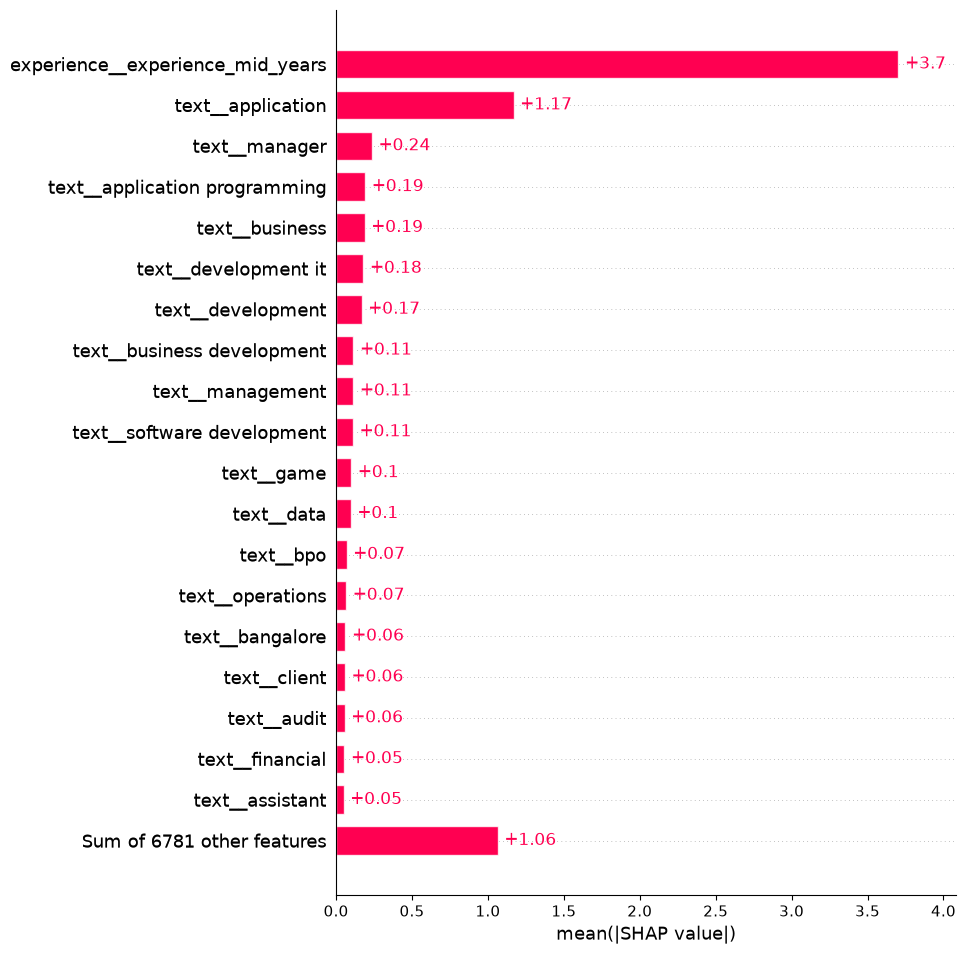

In [137]:
# Get the fitted preprocessing and XGBoost model from the current pipeline.
xgb_preprocessor = xgb_pipeline.named_steps["preprocessor"]
xgb_estimator = xgb_pipeline.named_steps["regressor"]

# Use small samples to keep SHAP calculation manageable.
background_rows = X_train_prepared.sample(
    n=min(50, len(X_train_prepared)),
    random_state=42,
)
explanation_rows = X_test_prepared.iloc[:30]

# Transform the rows into the numeric features used by XGBoost.
background_matrix = xgb_preprocessor.transform(background_rows)
explanation_matrix = xgb_preprocessor.transform(explanation_rows)

# Convert sparse matrices to regular arrays for SHAP.
if hasattr(background_matrix, "toarray"):
    background_matrix = background_matrix.toarray()
if hasattr(explanation_matrix, "toarray"):
    explanation_matrix = explanation_matrix.toarray()

feature_names = xgb_preprocessor.get_feature_names_out().tolist()

# Explain the XGBoost model using the training sample as a reference.
xgb_explainer = shap.TreeExplainer(
    xgb_estimator,
    data=background_matrix,
    feature_perturbation="interventional",
)
raw_xgb_shap = xgb_explainer(explanation_matrix)

# Build a fresh SHAP object with feature names supplied at creation.
xgb_shap_values = shap.Explanation(
    values=raw_xgb_shap.values,
    base_values=raw_xgb_shap.base_values,
    data=explanation_matrix,
    feature_names=feature_names,
)

# Display the 20 features with the largest average influence.
shap.plots.bar(xgb_shap_values, max_display=20)

Job title: Merchandiser, Female Only, kids Garment, 3yrs+,25k, Bangalore
Predicted salary: 3.32 LPA
Listed salary midpoint: 2.38 LPA


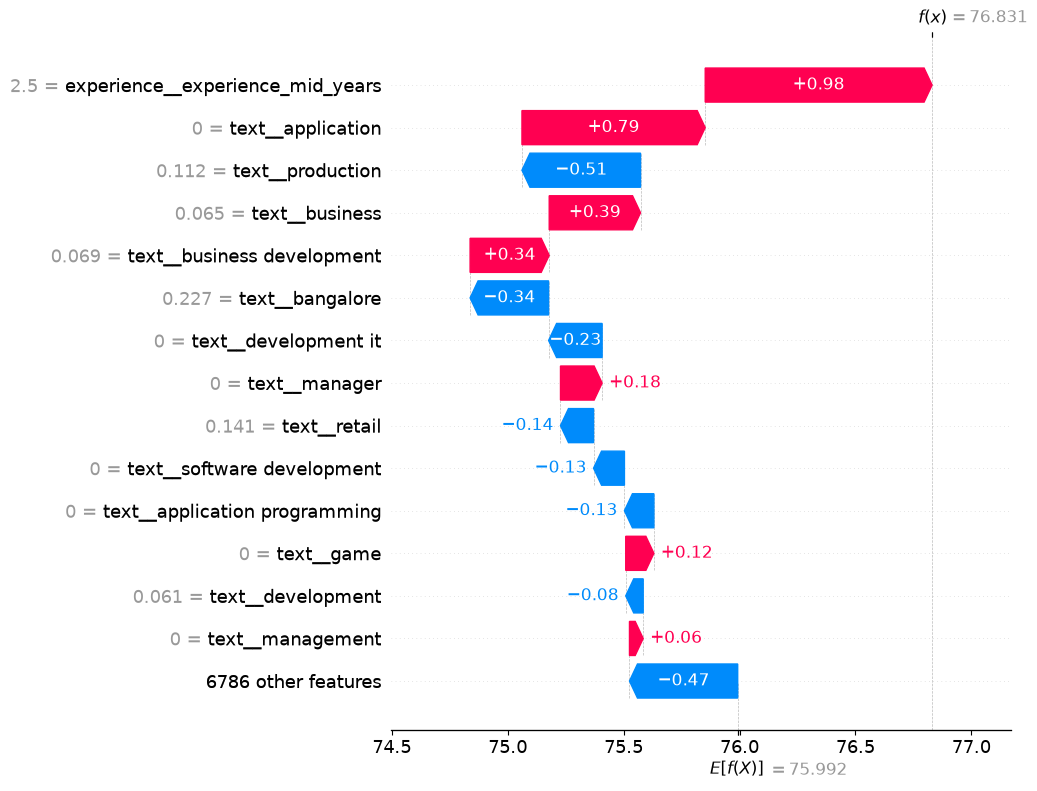

In [138]:
# Choose one held-back test posting.
row_position = 0
local_row = X_test_prepared.iloc[[row_position]]

local_prediction = xgb_pipeline.predict(local_row)[0]
local_actual = y_test.iloc[row_position]

print("Job title:", X_test.iloc[row_position]["Job Title"])
print(f"Predicted salary: {local_prediction:.2f} LPA")
print(f"Listed salary midpoint: {local_actual:.2f} LPA")

# Transform this posting and calculate its individual SHAP values.
local_matrix = xgb_preprocessor.transform(local_row)
if hasattr(local_matrix, "toarray"):
    local_matrix = local_matrix.toarray()

raw_local_shap = xgb_explainer(local_matrix)

local_explanation = shap.Explanation(
    values=raw_local_shap.values[0],
    base_values=raw_local_shap.base_values[0],
    data=local_matrix[0],
    feature_names=feature_names,
)

shap.plots.waterfall(local_explanation, max_display=15)


In [139]:
# Transform the same test posting used in the waterfall chart.
local_row = X_test_prepared.iloc[[row_position]]
local_transformed = xgb_preprocessor.transform(local_row)

if hasattr(local_transformed, "toarray"):
    local_dense = local_transformed.toarray()
else:
    local_dense = local_transformed

# Get predictions through both the full pipeline and the estimator alone.
pipeline_prediction = float(xgb_pipeline.predict(local_row)[0])
estimator_prediction = float(xgb_estimator.predict(local_dense)[0])

# Recalculate SHAP values for this exact transformed row.
diagnostic_shap = xgb_explainer(local_dense)
shap_prediction = float(
    diagnostic_shap.base_values[0] + diagnostic_shap.values[0].sum()
)

print(f"Pipeline prediction: {pipeline_prediction:.3f} LPA")
print(f"Estimator prediction: {estimator_prediction:.3f} LPA")
print(f"SHAP reconstructed prediction: {shap_prediction:.3f} LPA")

Pipeline prediction: 3.321 LPA
Estimator prediction: 76.831 LPA
SHAP reconstructed prediction: 76.831 LPA


In [140]:
import numpy as np

def dense_for_shap(matrix):
    """Convert sparse features to dense values while preserving XGBoost's missing zeros."""
    dense = matrix.toarray() if hasattr(matrix, "toarray") else np.asarray(matrix).copy()
    dense[dense == 0] = np.nan
    return dense

background_dense = dense_for_shap(background_sparse)
explanation_dense = dense_for_shap(explanation_sparse)

xgb_explainer = shap.TreeExplainer(
    xgb_estimator,
    data=background_dense,
    feature_perturbation="interventional",
)

one_row_shap = xgb_explainer(explanation_dense[:1])

pipeline_prediction = float(
    xgb_pipeline.predict(explanation_rows.iloc[[0]])[0]
)
shap_prediction = float(
    one_row_shap.base_values[0] + one_row_shap.values[0].sum()
)

print(f"Pipeline prediction: {pipeline_prediction:.3f} LPA")
print(f"SHAP reconstructed prediction: {shap_prediction:.3f} LPA")

Pipeline prediction: 3.321 LPA
SHAP reconstructed prediction: 3.321 LPA


In [141]:
import numpy as np

def make_dense_with_missing(matrix):
    """Convert a sparse matrix while preserving its missing-value behavior."""
    dense = matrix.toarray() if hasattr(matrix, "toarray") else matrix.copy()
    dense[dense == 0] = np.nan
    return dense


# Reuse the fitted preprocessing and the same test posting.
local_row = X_test_prepared.iloc[[row_position]]
local_sparse = xgb_preprocessor.transform(local_row)
local_dense = make_dense_with_missing(local_sparse)

background_sparse = xgb_preprocessor.transform(background_rows)
background_dense = make_dense_with_missing(background_sparse)

# Rebuild SHAP with dense data that preserves sparse missing values.
xgb_explainer = shap.TreeExplainer(
    xgb_estimator,
    data=background_dense,
    feature_perturbation="interventional",
)
local_shap = xgb_explainer(local_dense)

pipeline_prediction = float(xgb_pipeline.predict(local_row)[0])
estimator_prediction = float(xgb_estimator.predict(local_dense)[0])
shap_prediction = float(local_shap.base_values[0] + local_shap.values[0].sum())

print(f"Pipeline prediction: {pipeline_prediction:.3f} LPA")
print(f"Estimator prediction: {estimator_prediction:.3f} LPA")
print(f"SHAP reconstructed prediction: {shap_prediction:.3f} LPA")


Pipeline prediction: 3.321 LPA
Estimator prediction: 3.321 LPA
SHAP reconstructed prediction: 3.321 LPA


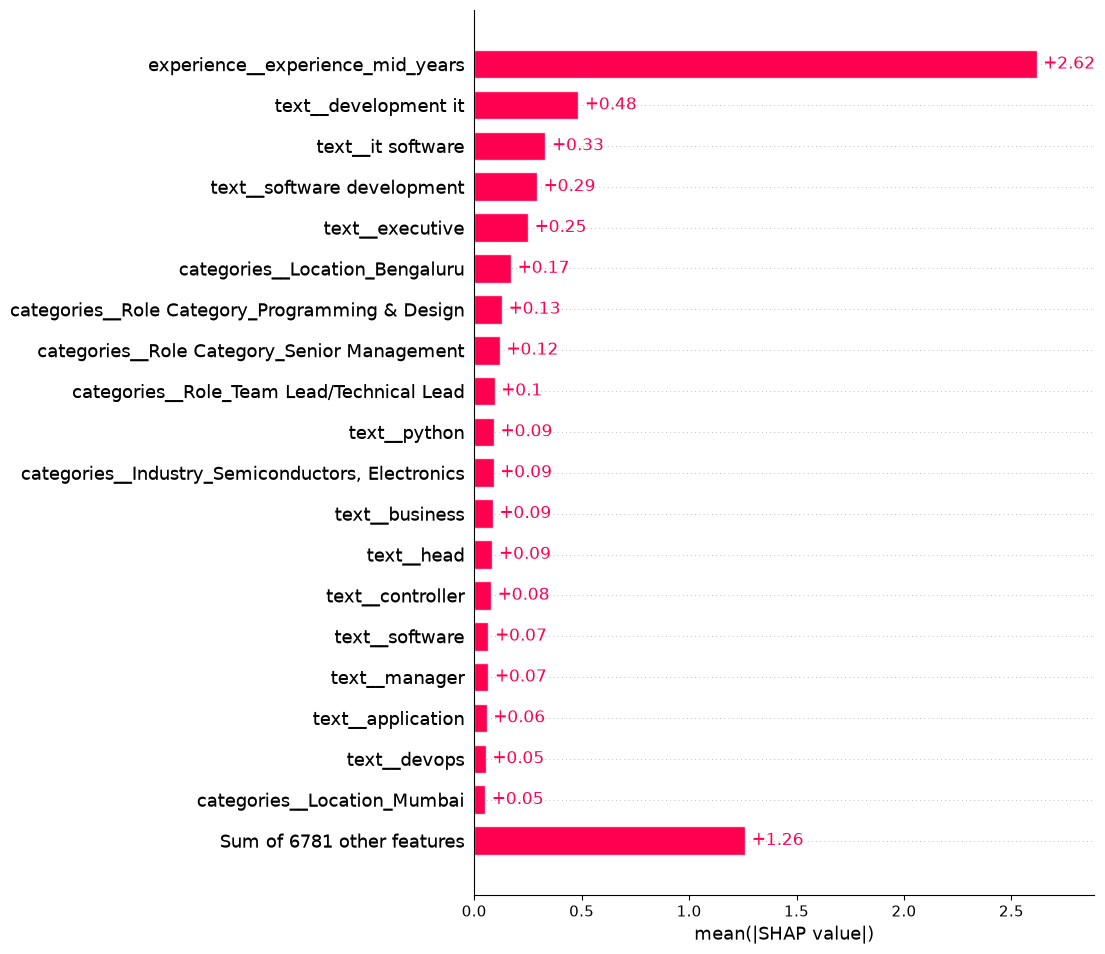

In [142]:
# Explain the same 30 held-back postings using sparse-compatible values.
explanation_rows = X_test_prepared.iloc[:30]
explanation_sparse = xgb_preprocessor.transform(explanation_rows)
explanation_dense = make_dense_with_missing(explanation_sparse)

# Calculate SHAP contributions with the corrected representation.
raw_xgb_shap = xgb_explainer(explanation_dense)

# Show zero-valued features as 0 in the chart, while keeping the SHAP
# calculations consistent with XGBoost's missing-value behavior.
display_data = np.nan_to_num(explanation_dense, nan=0.0)

xgb_shap_values = shap.Explanation(
    values=raw_xgb_shap.values,
    base_values=raw_xgb_shap.base_values,
    data=display_data,
    feature_names=xgb_preprocessor.get_feature_names_out().tolist(),
)

shap.plots.bar(xgb_shap_values, max_display=20)

Job title: Merchandiser, Female Only, kids Garment, 3yrs+,25k, Bangalore
Predicted salary: 3.32 LPA
Listed salary midpoint: 2.38 LPA


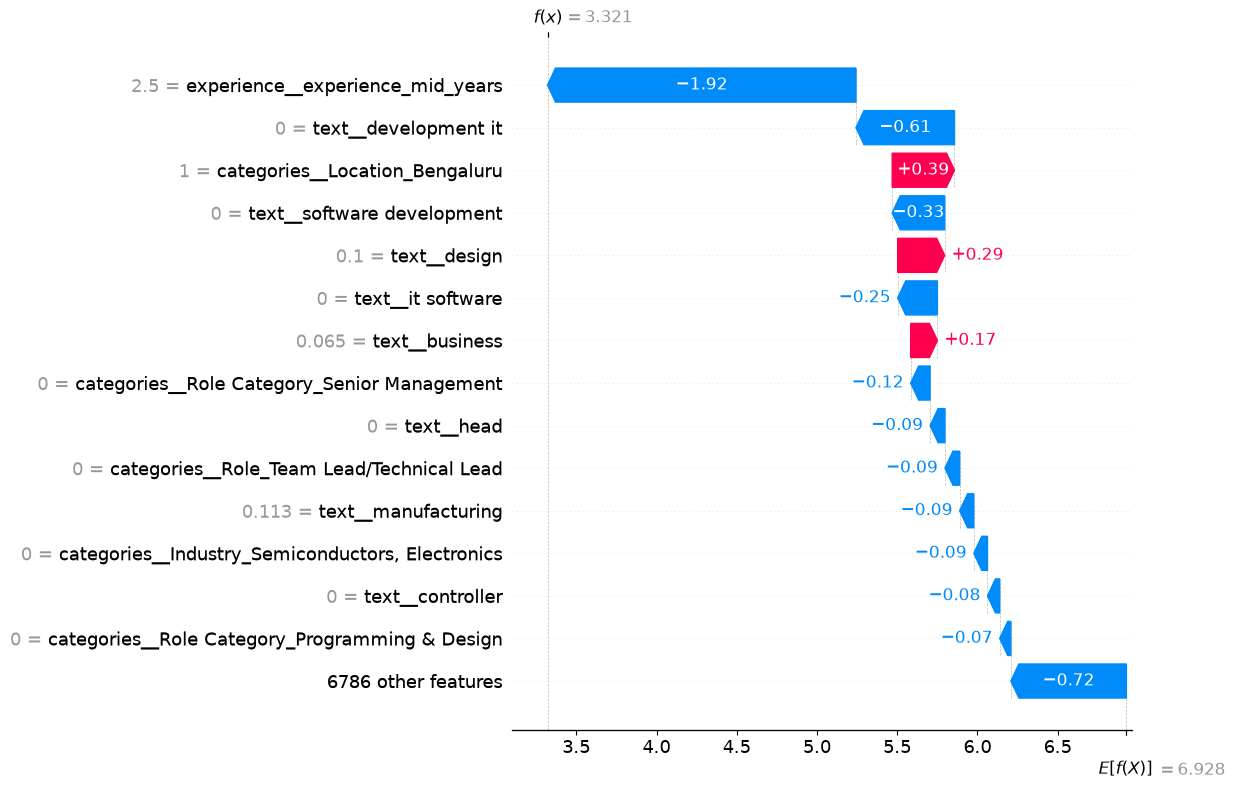

In [143]:
row_position = 0

print("Job title:", X_test.iloc[row_position]["Job Title"])
print(f"Predicted salary: {xgb_pipeline.predict(X_test_prepared.iloc[[row_position]])[0]:.2f} LPA")
print(f"Listed salary midpoint: {y_test.iloc[row_position]:.2f} LPA")

# Explain this same posting from the corrected global SHAP calculation.
shap.plots.waterfall(xgb_shap_values[row_position], max_display=15)

In [144]:
import matplotlib.pyplot as plt

# Create the output folder if it does not already exist.
figure_folder = project_root / "reports" / "figures"
figure_folder.mkdir(parents=True, exist_ok=True)

# Save the corrected global chart.
shap.plots.bar(xgb_shap_values, max_display=20, show=False)
plt.gcf().savefig(
    figure_folder / "salary_shap_global.png",
    dpi=200,
    bbox_inches="tight",
)
plt.close()

# Save the corrected local chart for the first test posting.
shap.plots.waterfall(xgb_shap_values[0], max_display=15, show=False)
plt.gcf().savefig(
    figure_folder / "salary_shap_example.png",
    dpi=200,
    bbox_inches="tight",
)
plt.close()

print("Saved:", figure_folder / "salary_shap_global.png")
print("Saved:", figure_folder / "salary_shap_example.png")

Saved: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\reports\figures\salary_shap_global.png
Saved: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\reports\figures\salary_shap_example.png


In [145]:
import joblib
import shap
import xgboost

# Create the model folder and save the fitted pipeline.
model_folder = project_root / "models"
model_folder.mkdir(parents=True, exist_ok=True)
model_path = model_folder / "salary_xgb_pipeline.joblib"

joblib.dump(xgb_pipeline, model_path)

# Reload it and compare one prediction with the original pipeline.
loaded_model = joblib.load(model_path)
sample_input = X_test_prepared.iloc[[0]]

original_prediction = float(xgb_pipeline.predict(sample_input)[0])
saved_prediction = float(loaded_model.predict(sample_input)[0])

print("Saved model:", model_path)
print(f"Original prediction: {original_prediction:.6f} LPA")
print(f"Reloaded prediction: {saved_prediction:.6f} LPA")
print("XGBoost version:", xgboost.__version__)
print("SHAP version:", shap.__version__)

assert abs(original_prediction - saved_prediction) < 1e-6

Saved model: c:\Users\Ramesh\OneDrive\Pictures\Desktop\Documents\india-job-market-rag-assistant\models\salary_xgb_pipeline.joblib
Original prediction: 3.320696 LPA
Reloaded prediction: 3.320696 LPA
XGBoost version: 3.2.0
SHAP version: 0.51.0


In [150]:
import re


def remove_salary_mentions(value):
    """Remove salary-like amounts from text features."""
    if pd.isna(value):
        return ""

    text = str(value)

    salary_patterns = [
        # Amounts such as "6-10 LPA", "1 Cr", or "25k".
        r"\b\d[\d,]*(?:\.\d+)?\s*(?:-\s*\d[\d,]*(?:\.\d+)?\s*)?"
        r"(?:lpa|lakhs?|lacs?|lcs|crores?|cr|k)\b",

        # Amounts such as "50,000 PA" or "12,000 per month".
        r"\b\d[\d,]*(?:\.\d+)?"
        r"(?:\s*(?:-|to)\s*\d[\d,]*(?:\.\d+)?)?\s*"
        r"(?:pa|p\.a\.?|per annum|per year|per month|monthly|pm|p\.m\.?)\b",

        # Currency-prefixed amounts such as "INR 3,00,000".
        r"(?:\binr\b|\brs\.?\b|₹)\s*\d[\d,]*"
        r"(?:\s*(?:-|to)\s*\d[\d,]*)?",
    ]

    for pattern in salary_patterns:
        text = re.sub(pattern, " ", text, flags=re.IGNORECASE)

    return re.sub(r"\s+", " ", text).strip()


In [151]:
def prepare_model_inputs(frame):
    """Remove salary hints and combine job text for modeling."""
    prepared = frame.copy()

    for column in text_columns:
        prepared[column] = prepared[column].map(remove_salary_mentions)

    prepared["job_text"] = (
        prepared["Job Title"]
        + " "
        + prepared["Key Skills"]
        + " "
        + prepared["Functional Area"]
    )

    return prepared.drop(columns=text_columns)

In [152]:
example_title = "Merchandiser, 3yrs+, 25k, Bangalore"
print(remove_salary_mentions(example_title))

Merchandiser, 3yrs+, , Bangalore


In [153]:
example_title = "Merchandiser, 3yrs+, 25k, Bangalore"
print(remove_salary_mentions(example_title))

Merchandiser, 3yrs+, , Bangalore
